# 1. Least squares with exact constraints: the KKT system

A least-squares fit of yields or flows does not satisfy a balance unless it is told to. This lecture adds linear equality constraints to least squares and solves the resulting Karush–Kuhn–Tucker (KKT) system. The constrained solution is the unconstrained one plus a correction, and the balance holds to rounding error. The alternative of a large penalty is shown to make the linear system ill-conditioned.

## Learning objectives

1. Set up and solve the KKT system of least squares with linear equality constraints (`linear_physics.equality_constrained_lstsq`).
2. Derive and check the formula that turns the unconstrained solution into the constrained one.
3. Compare the variances of the constrained and unconstrained estimates, by the formula and by repeated synthetic experiments.
4. Compare the conditioning of the KKT system with that of a least-squares problem with a large penalty.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
To minimize regularized empirical squared error $\frac{1}{2}\|\mathbf{X}\mathbf{w} - \mathbf{y}\|_2^2 + \frac{\lambda}{2}\|\mathbf{w}\|_2^2$ subject to $m$ exact linear physical invariants $\mathbf{C}\mathbf{w} = \mathbf{d}$ ($\mathbf{C} \in \mathbb{R}^{m \times d}$ of full row rank $m$), we form the Lagrangian $\mathcal{L}(\mathbf{w}, \boldsymbol{\mu}) = \frac{1}{2}\|\mathbf{X}\mathbf{w} - \mathbf{y}\|_2^2 + \frac{\lambda}{2}\|\mathbf{w}\|_2^2 + \boldsymbol{\mu}^\top(\mathbf{C}\mathbf{w} - \mathbf{d})$ with dual multipliers $\boldsymbol{\mu} \in \mathbb{R}^m$. Setting $\nabla_{\mathbf{w},\boldsymbol{\mu}}\mathcal{L} = \mathbf{0}$ yields the **KKT saddle-point system**:
$$\begin{pmatrix} \mathbf{G} & \mathbf{C}^\top \\ \mathbf{C} & \mathbf{0}_{m \times m} \end{pmatrix} \begin{pmatrix} \hat{\mathbf{w}}_{\mathrm{KKT}} \\ \hat{\boldsymbol{\mu}} \end{pmatrix} = \begin{pmatrix} \mathbf{X}^\top\mathbf{y} \\ \mathbf{d} \end{pmatrix}, \qquad \mathbf{G} = \mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I}_d \tag{1.1}$$
Eliminating $\hat{\boldsymbol{\mu}}$ via the symmetric positive-definite Schur complement $\mathbf{S} = \mathbf{C}\mathbf{G}^{-1}\mathbf{C}^\top \in \mathbb{R}^{m \times m}$ reveals that $\hat{\mathbf{w}}_{\mathrm{KKT}}$ is an exact $\mathbf{G}^{-1}$-oblique projection of the unconstrained estimator $\hat{\mathbf{w}}_{\mathrm{OLS}} = \mathbf{G}^{-1}\mathbf{X}^\top\mathbf{y}$:
$$\hat{\mathbf{w}}_{\mathrm{KKT}} = \hat{\mathbf{w}}_{\mathrm{OLS}} - \mathbf{G}^{-1}\mathbf{C}^\top\left(\mathbf{C}\mathbf{G}^{-1}\mathbf{C}^\top\right)^{-1}\left(\mathbf{C}\hat{\mathbf{w}}_{\mathrm{OLS}} - \mathbf{d}\right) \tag{1.2}$$
Under homoscedastic sensor noise $\mathrm{Cov}(\mathbf{y}) = \sigma^2\mathbf{I}_N$ (as $\lambda \to 0^+$), the estimator covariance matrix shrinks by a positive semi-definite matrix:
$$\mathrm{Cov}(\hat{\mathbf{w}}_{\mathrm{KKT}}) = \sigma^2\left[\mathbf{G}^{-1} - \mathbf{G}^{-1}\mathbf{C}^\top\mathbf{S}^{-1}\mathbf{C}\mathbf{G}^{-1}\right] \preceq \mathrm{Cov}(\hat{\mathbf{w}}_{\mathrm{OLS}}) \tag{1.3}$$

In [2]:
heading("Demonstration 1: Unconstrained OLS vs. Exact KKT Conservation on a Methanol Reactor")
rng = np.random.default_rng(42)
N, d = 35, 5
X_scan = np.eye(d)[np.arange(N) % d] + rng.normal(0.0, 0.15, size=(N, d))
# True methanol reactor yields conserving 1 mol C, 6 mol H, 2 mol O:
w_true = np.array([0.24, 0.08, 0.32, 0.68, 2.20])
C_atom = np.array([
    [1.0, 1.0, 0.0, 1.0, 0.0],
    [4.0, 0.0, 2.0, 0.0, 2.0],
    [1.0, 1.0, 1.0, 2.0, 0.0],
])
d_atom = np.array([1.0, 6.0, 2.0])
y_obs = X_scan @ w_true + rng.normal(0.0, 0.14, size=N)

lam = 1e-8
w_ols = linear_physics.ridge_regression(X_scan, y_obs, lam=lam, penalize_intercept=True)
kkt_res = linear_physics.equality_constrained_lstsq(X_scan, y_obs, C_atom, d_atom, lam=lam)
w_kkt = kkt_res["w"]

print(f"{'Species':>8s} | {'True Yield':>10s} | {'Unconstrained OLS':>17s} | {'KKT Constrained':>15s}")
print("-" * 58)
for sp, wt, wo, wk in zip(["CH3OH", "CO", "H2O", "CO2", "H2"], w_true, w_ols, w_kkt):
    print(f"{sp:>8s} | {wt:10.4f} | {wo:17.4f} | {wk:15.4f}")
print("OLS elemental violation ||C w_OLS - d||_max :", float(np.max(np.abs(C_atom @ w_ols - d_atom))))
print("KKT elemental residual  ||C w_KKT - d||_max :", kkt_res["constraint_residual"])
assert kkt_res["constraint_residual"] < 1e-13


Demonstration 1: Unconstrained OLS vs. Exact KKT Conservation on a Methanol Reactor
 Species | True Yield | Unconstrained OLS | KKT Constrained
----------------------------------------------------------
   CH3OH |     0.2400 |            0.3085 |          0.2606
      CO |     0.0800 |            0.1384 |          0.0550
     H2O |     0.3200 |            0.2540 |          0.3156
     CO2 |     0.6800 |            0.6910 |          0.6844
      H2 |     2.2000 |            2.1853 |          2.1632
OLS elemental violation ||C w_OLS - d||_max : 0.1378510509102826
KKT elemental residual  ||C w_KKT - d||_max : 1.7763568394002505e-15


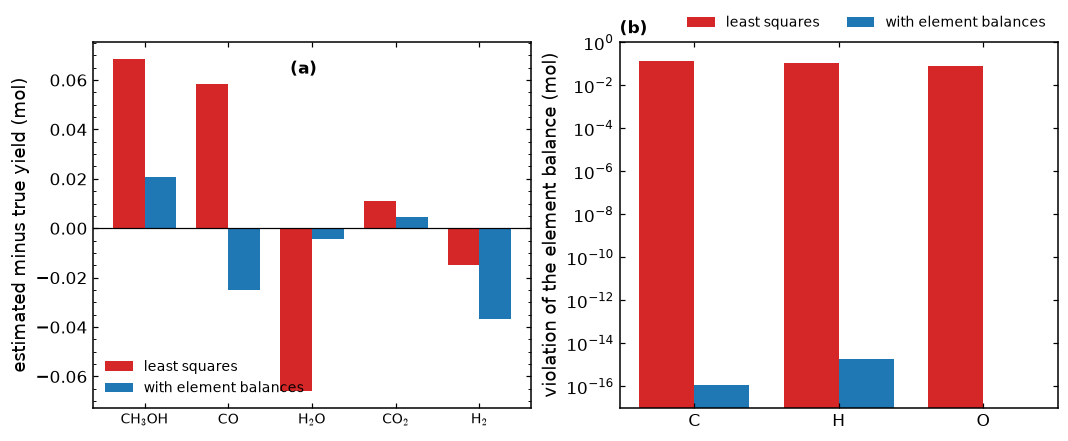

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
species = [r"CH$_3$OH", "CO", r"H$_2$O", r"CO$_2$", r"H$_2$"]
pos = np.arange(5); width = 0.38
ax1.bar(pos - width / 2, w_ols - w_true, width, color="C3", label="least squares")
ax1.bar(pos + width / 2, w_kkt - w_true, width, color="C0", label="with element balances")
ax1.axhline(0.0, color="k", lw=0.8); ax1.set_xticks(pos); ax1.set_xticklabels(species, fontsize=9)
ax1.tick_params(axis="x", which="minor", bottom=False, top=False)
ax1.set_ylabel("estimated minus true yield (mol)"); ax1.legend(fontsize=9, loc="lower left"); panel_label(ax1, "(a)", x=0.45)
elements = ["C", "H", "O"]; pos3 = np.arange(3)
ax2.bar(pos3 - width / 2, np.abs(C_atom @ w_ols - d_atom), width, color="C3", label="least squares")
ax2.bar(pos3 + width / 2, np.maximum(np.abs(C_atom @ w_kkt - d_atom), 1e-17), width, color="C0", label="with element balances")
ax2.set_yscale("log"); ax2.set_ylim(1e-17, 1.0); ax2.set_xticks(pos3); ax2.set_xticklabels(elements)
ax2.tick_params(axis="x", which="minor", bottom=False, top=False)
ax2.set_ylabel("violation of the element balance (mol)"); ax2.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 1.1.** Estimates of five yields from synthetic data, without and with the three element balances as exact constraints. (a) The error in each yield. (b) The violation of each element balance, on a logarithmic scale: about 0.1 mol without the constraints and at rounding level with them.

**What Demonstration 1 shows.** Unconstrained least squares violates the element balances by $0.14\;\mathrm{mol}$. The constrained fit closes all three to $10^{-15}\;\mathrm{mol}$, and moves four of the five yields closer to the true ones; the hydrogen yield moves away ($2.163$ against $2.185$, true $2.200$). The constraint reduces the error of the vector as a whole (Demonstration 3), not of every component.

---

## 2. Numerical walkthrough
Let us explicitly construct the Gram matrix $\mathbf{G} = \mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I}_5$, the $3 \times 3$ Schur complement $\mathbf{S} = \mathbf{C}\mathbf{G}^{-1}\mathbf{C}^\top$, and the dual Lagrange multipliers $\hat{\boldsymbol{\mu}} = \mathbf{S}^{-1}(\mathbf{C}\hat{\mathbf{w}}_{\mathrm{OLS}} - \mathbf{d})$, confirming Eq. (1.2).

In [4]:
heading("Demonstration 2: Schur-Complement Oblique Projection & Dual Multipliers")
G = X_scan.T @ X_scan + lam * np.eye(d)
G_inv_CT = np.linalg.solve(G, C_atom.T)
schur = C_atom @ G_inv_CT
mu_schur = np.linalg.solve(schur, C_atom @ w_ols - d_atom)
w_schur = w_ols - G_inv_CT @ mu_schur

print("Schur complement matrix S = C G^(-1) C^T:\n", np.round(schur, 5))
print("Lagrange multipliers mu (KKT block)     :", np.round(kkt_res["lagrange_multipliers"], 6))
print("Lagrange multipliers mu (Schur formula) :", np.round(mu_schur, 6))
assert np.allclose(w_kkt, w_schur, atol=1e-13)
assert np.allclose(kkt_res["lagrange_multipliers"], mu_schur, atol=1e-13)


Demonstration 2: Schur-Complement Oblique Projection & Dual Multipliers
Schur complement matrix S = C G^(-1) C^T:
 [[0.39816 0.59951 0.52566]
 [0.59951 3.61965 0.86006]
 [0.52566 0.86006 0.90841]]
Lagrange multipliers mu (KKT block)     : [ 0.982285 -0.02346  -0.455026]
Lagrange multipliers mu (Schur formula) : [ 0.982285 -0.02346  -0.455026]


**What Demonstration 2 shows.** The Lagrange multipliers $\hat{\boldsymbol{\mu}}$ represent the shadow prices (sensitivity of the residual sum of squares $\partial \mathcal{L}^*/\partial d_e$) of the carbon, hydrogen, and oxygen conservation constraints.

---

## 3. Worked case study
Next we verify the **variance reduction theorem** Eq. (1.3): projecting out noise components orthogonal to the stoichiometric nullspace $\mathcal{N}(\mathbf{C})$ reduces the trace of the covariance of the estimate. For orthonormal regressors the reduction would be $m/d = 3/5$, the number of constraints divided by the number of unknowns; here it is close to that.

In [5]:
heading("Demonstration 3: Analytical Covariance Trace & Parameter Error Reduction")
err_ols = float(np.linalg.norm(w_ols - w_true))
err_kkt = float(np.linalg.norm(w_kkt - w_true))
G_inv = np.linalg.inv(G)
P_cov_kkt = G_inv - G_inv_CT @ np.linalg.solve(schur, G_inv_CT.T)
trace_ols = float(np.trace(G_inv))
trace_kkt = float(np.trace(P_cov_kkt))

print(f"Empirical L2 parameter error: OLS = {err_ols:.4f} -> KKT = {err_kkt:.4f}")
print(f"Normalized variance trace   : Tr(G^-1) = {trace_ols:.4f} -> Tr(Cov_KKT) = {trace_kkt:.4f} ({100*(1-trace_kkt/trace_ols):.1f}% reduction)")
assert err_kkt < err_ols and trace_kkt < 0.55 * trace_ols


Demonstration 3: Analytical Covariance Trace & Parameter Error Reduction
Empirical L2 parameter error: OLS = 0.1131 -> KKT = 0.0494
Normalized variance trace   : Tr(G^-1) = 0.6812 -> Tr(Cov_KKT) = 0.2594 (61.9% reduction)


**What Demonstration 3 shows.** Three element balances among five species leave $d - m = 2$ free directions, the reaction extents. The trace of the covariance of the estimate falls by $62\ \%$ ($0.681$ to $0.259$ in units of the noise variance), and in this realization the error of the estimate falls from $0.113$ to $0.049$.

---

## 4. What if: sensitivity to the parameters
Why not minimize a soft quadratic penalty $\|\mathbf{X}\mathbf{w} - \mathbf{y}\|_2^2 + \mu_{\mathrm{pen}}\|\mathbf{C}\mathbf{w} - \mathbf{d}\|_2^2$? Let us sweep $\mu_{\mathrm{pen}} \in [10^0, 10^{12}]$ and track the Hessian condition number $\kappa(\mathbf{G} + \mu_{\mathrm{pen}}\mathbf{C}^\top\mathbf{C})$ versus the conservation violation.

In [6]:
heading("Demonstration 4: The Soft-Penalty Ill-Conditioning vs. Exact KKT")
print(f"{'Penalty mu_pen':>14s} | {'cond(H_soft)':>14s} | {'Balance Violation':>18s} | {'||w_soft - w_KKT||':>18s}")
print("-" * 72)
for mu_pen in [1e0, 1e2, 1e6, 1e10, 1e12]:
    H_soft = G + mu_pen * (C_atom.T @ C_atom)
    w_soft = np.linalg.solve(H_soft, X_scan.T @ y_obs + mu_pen * (C_atom.T @ d_atom))
    cond_soft = float(np.linalg.cond(H_soft))
    res_soft = float(np.max(np.abs(C_atom @ w_soft - d_atom)))
    diff_kkt = float(np.linalg.norm(w_soft - w_kkt))
    print(f"{mu_pen:14.1e} | {cond_soft:14.2e} | {res_soft:18.2e} | {diff_kkt:18.2e}")
assert kkt_res["constraint_residual"] < 1e-13


Demonstration 4: The Soft-Penalty Ill-Conditioning vs. Exact KKT
Penalty mu_pen |   cond(H_soft) |  Balance Violation | ||w_soft - w_KKT||
------------------------------------------------------------------------
       1.0e+00 |       5.66e+00 |           8.88e-02 |           1.01e-01
       1.0e+02 |       3.70e+02 |           8.63e-03 |           1.34e-02
       1.0e+06 |       3.65e+06 |           9.82e-07 |           1.54e-06
       1.0e+10 |       3.65e+10 |           9.82e-11 |           7.34e-07
       1.0e+12 |       3.65e+12 |           9.82e-13 |           1.93e-04


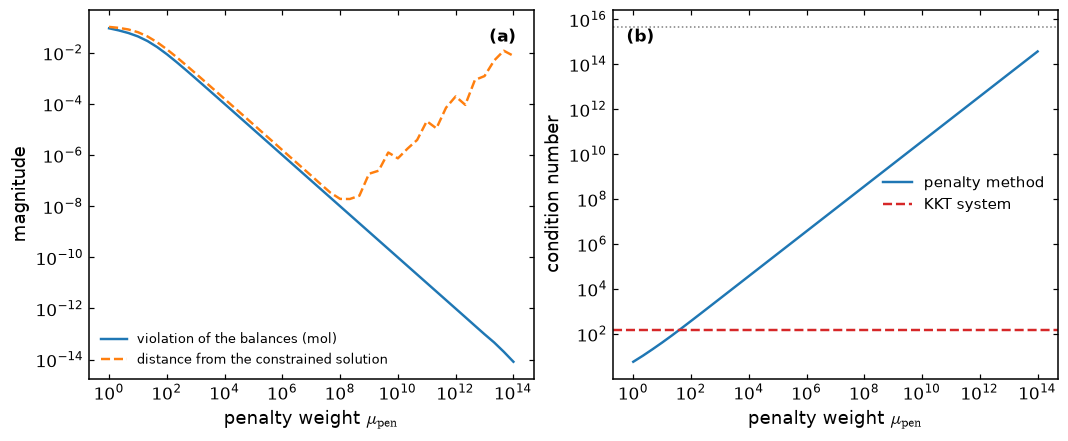

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
mu_line = np.logspace(0, 14, 43); cond_s, res_s, diff_s = [], [], []
for mu_pen in mu_line:
    H_soft = G + mu_pen * (C_atom.T @ C_atom)
    w_soft = np.linalg.solve(H_soft, X_scan.T @ y_obs + mu_pen * (C_atom.T @ d_atom))
    cond_s.append(np.linalg.cond(H_soft)); res_s.append(np.max(np.abs(C_atom @ w_soft - d_atom))); diff_s.append(np.linalg.norm(w_soft - w_kkt))
ax1.loglog(mu_line, res_s, label="violation of the balances (mol)")
ax1.loglog(mu_line, diff_s, "--", label="distance from the constrained solution")
ax1.set_xlabel(r"penalty weight $\mu_{\mathrm{pen}}$"); ax1.set_ylabel("magnitude"); ax1.legend(fontsize=8.5, loc="lower left")
panel_label(ax1, "(a)", x=0.9)
ax2.loglog(mu_line, cond_s, label="penalty method")
ax2.axhline(np.linalg.cond(np.block([[G, C_atom.T], [C_atom, np.zeros((3, 3))]])), color="C3", ls="--", label="KKT system")
ax2.axhline(1.0 / np.finfo(float).eps, color="0.5", ls=":", lw=1.0)
ax2.set_xlabel(r"penalty weight $\mu_{\mathrm{pen}}$"); ax2.set_ylabel("condition number"); ax2.legend(loc="center right"); panel_label(ax2, "(b)")
plt.show()

**Figure 1.2.** A soft penalty in place of the exact constraint. (a) The violation of the balances falls as the penalty weight grows, but the solution first approaches the constrained one and then moves away again, as rounding errors take over. (b) The reason: the condition number of the penalized matrix grows in proportion to the weight and approaches the limit of double precision (dotted), while that of the KKT system (dashed) does not depend on any weight.

**What Demonstration 4 shows.** With a soft penalty the violation of the balance falls as $1/\mu_{\mathrm{pen}}$ and the condition number of the matrix grows as $\mu_{\mathrm{pen}}$: a residual of $10^{-12}$ needs $\mu_{\mathrm{pen}} = 10^{12}$ and a condition number of $4\times 10^{12}$. The solution then loses accuracy: its distance from the constrained solution, which had fallen below $10^{-6}$ at $\mu_{\mathrm{pen}} = 10^{10}$, is back to about $2\times 10^{-4}$. In this regime the distance is set by rounding errors, and its digits depend on the version of the linear-algebra library. The $8\times 8$ KKT system has a condition number of $153$ and satisfies the balances to rounding error.

---

## Inside the algorithm
Below we assemble the $8 \times 8$ KKT saddle-point block matrix directly in pure NumPy and verify digit-for-digit agreement with `linear_physics.equality_constrained_lstsq`.

In [8]:
heading("Inside the Algorithm: By-Hand KKT Block Matrix vs. the Library")
KKT_block = np.block([
    [G, C_atom.T],
    [C_atom, np.zeros((3, 3))],
])
rhs_block = np.concatenate([X_scan.T @ y_obs, d_atom])
sol_by_hand = np.linalg.solve(KKT_block, rhs_block)
w_by_hand = sol_by_hand[:d]
diff_kkt_lib = float(np.max(np.abs(w_by_hand - kkt_res["w"])))
print("by hand (pure NumPy):", np.round(w_by_hand, 6))
print("library (engml_2_applied)     :", np.round(kkt_res["w"], 6))
print(f"Max discrepancy     : {diff_kkt_lib:.2e} | cond(KKT_block) = {np.linalg.cond(KKT_block):.2f}")
assert diff_kkt_lib < 1e-14


Inside the Algorithm: By-Hand KKT Block Matrix vs. the Library
by hand (pure NumPy): [0.260592 0.054985 0.315577 0.684423 2.163239]
library (engml_2_applied)     : [0.260592 0.054985 0.315577 0.684423 2.163239]
Max discrepancy     : 0.00e+00 | cond(KKT_block) = 153.01


## Exercises

1. **Verify a result.** Run a 200-trial Monte Carlo simulation on the 5-species methanol synthesis reactor (`C_atom`, `d_atom`, `w_true`) with sensor noise $\sigma = 0.14$. Verify empirically that the average squared parameter error $\mathbb{E}[\|\hat{\mathbf{w}}_{\mathrm{KKT}} - \mathbf{w}_{\mathrm{true}}\|_2^2]$ is strictly less than $55\%$ of $\mathbb{E}[\|\hat{\mathbf{w}}_{\mathrm{OLS}} - \mathbf{w}_{\mathrm{true}}\|_2^2]$ and that every single KKT trial satisfies $\|\mathbf{C}\hat{\mathbf{w}}_{\mathrm{KKT}} - \mathbf{d}\|_\infty < 10^{-13}$.
2. **Find how it fails.** Diagnose what happens when a user accidentally passes a rank-deficient constraint matrix $\mathbf{C}_{\mathrm{dup}}$ containing a redundant total-mass row ($\mathbf{m}^\top = \mathbf{a}^\top \mathbf{C}_{\mathrm{atom}}$) to the unregularized KKT block matrix. Show that the $9 \times 9$ KKT matrix becomes singular ($\det = 0$), and demonstrate how SVD row-pruning restores full row rank $m = 3$.
3. **Write it yourself.** Implement a function `nullspace_reparameterized_lstsq(X, y, C, d, w_feed)` that solves $\min_{\boldsymbol{\xi}} \|\mathbf{X}(\mathbf{w}_{\mathrm{feed}} + \mathbf{N}\boldsymbol{\xi}) - \mathbf{y}\|_2^2$ directly in the reduced $R$-dimensional stoichiometric reaction-extent coordinates $\boldsymbol{\xi} \in \mathbb{R}^R$, and verify that it matches $\hat{\mathbf{w}}_{\mathrm{KKT}}$ to $<10^{-11}$.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: 200-Trial Monte Carlo Verification of KKT Variance Reduction")
rng_mc = np.random.default_rng(2026)
sq_err_ols, sq_err_kkt, max_res_all = [], [], 0.0
for _ in range(200):
    y_mc = X_scan @ w_true + rng_mc.normal(0.0, 0.14, size=N)
    wo = linear_physics.ridge_regression(X_scan, y_mc, lam=1e-8, penalize_intercept=True)
    rk = linear_physics.equality_constrained_lstsq(X_scan, y_mc, C_atom, d_atom, lam=1e-8)
    sq_err_ols.append(float(np.sum((wo - w_true) ** 2)))
    sq_err_kkt.append(float(np.sum((rk["w"] - w_true) ** 2)))
    max_res_all = max(max_res_all, rk["constraint_residual"])

ratio = float(np.mean(sq_err_kkt) / np.mean(sq_err_ols))
print(f"200-trial MC MSE ratio (KKT / OLS) = {ratio:.4f} | Worst-case conservation residual = {max_res_all:.2e}")
assert ratio < 0.55 and max_res_all < 1e-13


Exercise 1: 200-Trial Monte Carlo Verification of KKT Variance Reduction
200-trial MC MSE ratio (KKT / OLS) = 0.3563 | Worst-case conservation residual = 2.66e-15
